# Explore a fasim run

Load an HDF5 run, browse gathers, re-pick onsets with other picker settings without re-simulating.

In [1]:
import sys, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, '..')
from fasim.io import load_run
from fasim.onset import pick_gather, wavelet_onset, emergence_delay, PICKERS
from fasim import plot as fplot
from fasim.geometry import offsets
import dataclasses

RUN = '../runs/sanity_notunnel_hires/run.h5'   # <- change
r = load_run(RUN)
cfg = r.cfg
print(cfg.name, r.data.shape, '(shot, rcv, comp, nt)', 'dt =', (r.t[1]-r.t[0])*1e6, 'us')
print('wavelet onset rel. peak:', r.attrs['wavelet_onset']*1e3, 'ms;  s/shot:', r.attrs['seconds_per_shot'])
r.rcv_names

homogeneous (24, 4, 3, 1440) (shot, rcv, comp, nt) dt = 20.832999999999615 us
wavelet onset rel. peak: -1.3399143167205072 ms;  s/shot: 1.0133949566225056


['RCV1', 'RCV2', 'RCV3', 'RCV4']

## Model and acquisition

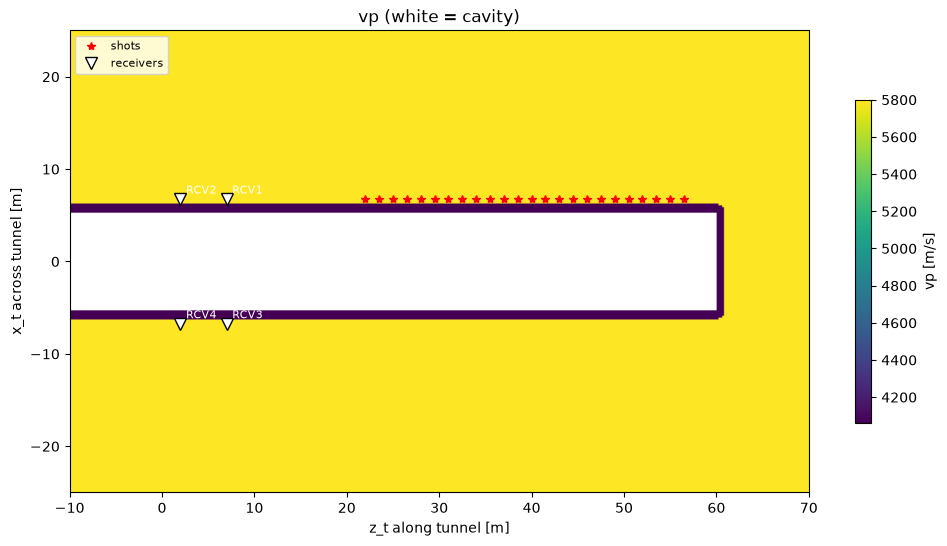

In [2]:
fig, ax = plt.subplots(figsize=(12, 6))
fplot.plot_model(r.model, r.grid, r.src_pos, r.rcv_pos, r.rcv_names, ax=ax)
plt.show()

## Receiver gather with stored labels
`comp`: 0 = v along tunnel, 1 = v across tunnel, 2 = pressure.

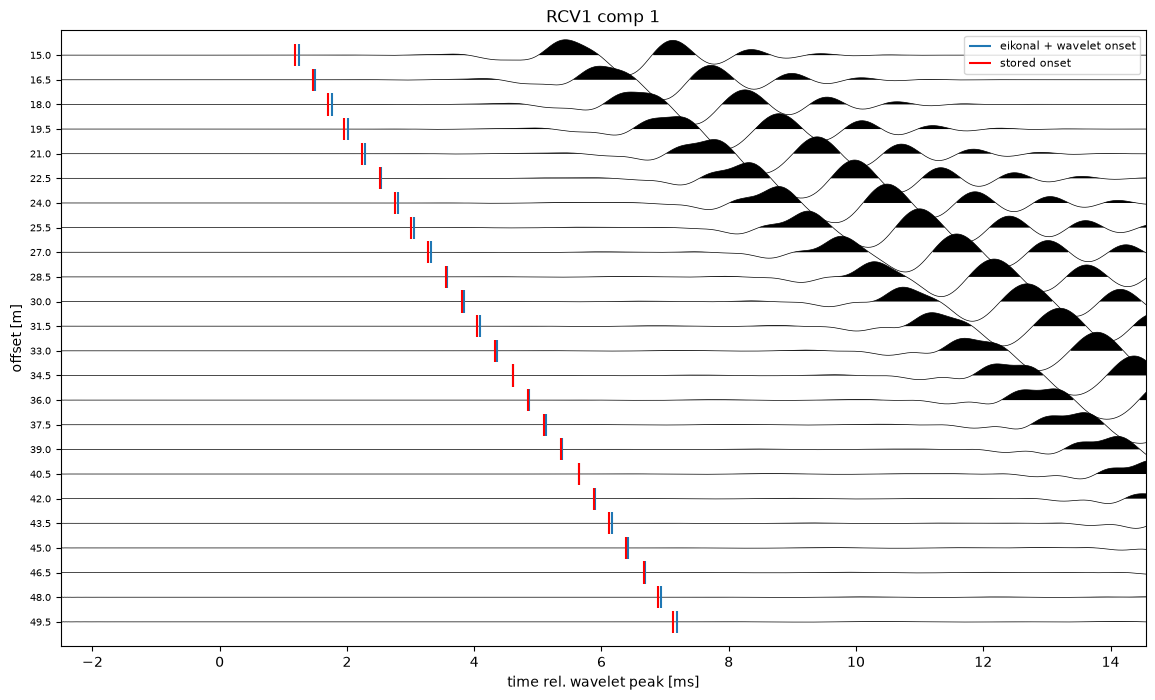

In [3]:
rcv, comp = 0, 1
picks = {'eikonal + wavelet onset': (r.eikonal[:, rcv, min(comp, 1)] + r.attrs['wavelet_onset'], 'tab:blue'),
         'stored onset': (r.onset[:, rcv, comp], 'r')}
fig, ax = plt.subplots(figsize=(14, 8))
fplot.plot_gather(r.data[:, rcv, comp], r.t, labels=r.offset[:, rcv], picks=picks, ax=ax,
                  tmax=np.nanmax(r.eikonal[:, rcv]) + 6e-3, title=f'{r.rcv_names[rcv]} comp {comp}', ylabel='offset [m]')
plt.show()

## Re-pick with different settings
Change the `LabelCfg` fields below (picker, rel_threshold, threshold_ref, ref_window_ms, component, search_before_ms, sta/lta, trigger).

wavelet onset -1.4650015744896723 ms


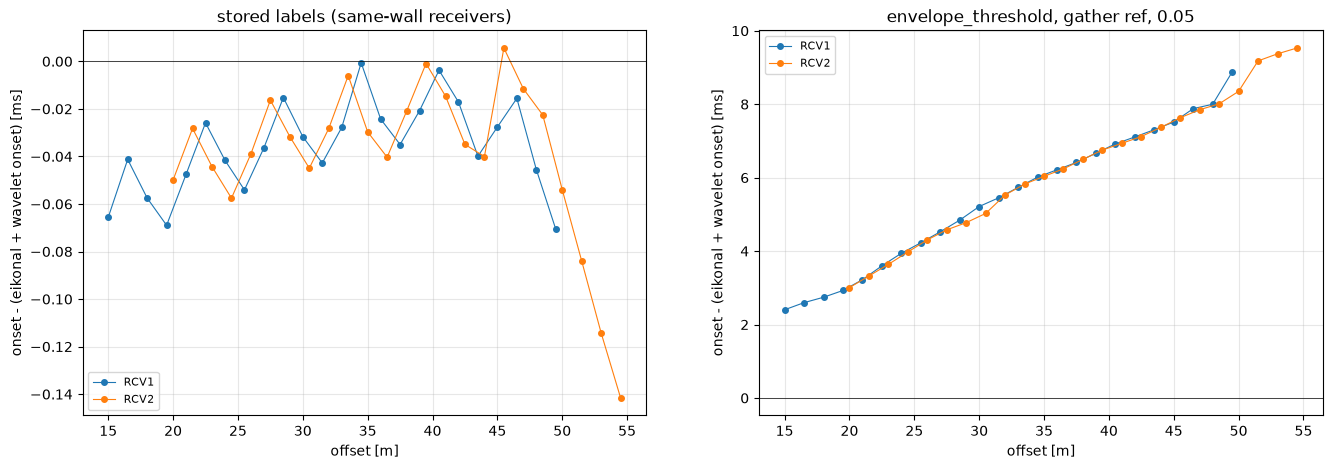

In [4]:
lc = dataclasses.replace(cfg.labels, picker='envelope_threshold', rel_threshold=0.05, threshold_ref='gather', component='x')
w_on = wavelet_onset(r.wavelet, r.t[1]-r.t[0], r.attrs['peak_time'], lc)
onset2 = pick_gather(r.data, r.t, lc, eikonal=r.eikonal, w_onset=w_on)
eik4 = np.concatenate([r.eikonal, r.eikonal[:, :, 1:2]], axis=2)
delay2 = emergence_delay(onset2, eik4, w_on)
print('wavelet onset', w_on*1e3, 'ms')

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
same_wall = [i for i, n in enumerate(r.rcv_names) if cfg.acquisition.receivers[i].side == cfg.acquisition.shot_side]
fplot.plot_delay_vs_offset(r.offset[:, same_wall], r.delay[:, same_wall, -1], [r.rcv_names[i] for i in same_wall], ax=axes[0], title='stored labels (same-wall receivers)')
fplot.plot_delay_vs_offset(r.offset[:, same_wall], delay2[:, same_wall, -1], [r.rcv_names[i] for i in same_wall], ax=axes[1], title=f'{lc.picker}, {lc.threshold_ref} ref, {lc.rel_threshold}')
plt.show()

## Compare pickers on one trace

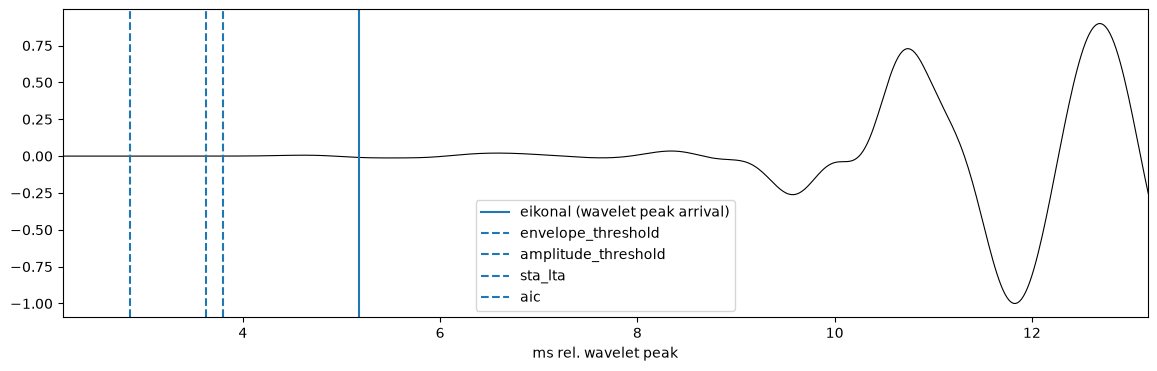

In [5]:
shot, rcv, comp = 10, 0, 1
tr = r.data[shot, rcv, comp]; dt = r.t[1]-r.t[0]
i0 = np.searchsorted(r.t, r.eikonal[shot, rcv, min(comp,1)] + r.attrs['wavelet_onset'] - 1.0e-3)
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(r.t*1e3, tr/np.abs(tr).max(), 'k', lw=0.8)
ax.axvline(r.eikonal[shot, rcv, min(comp,1)]*1e3, color='tab:blue', label='eikonal (wavelet peak arrival)')
for name, fn in PICKERS.items():
    kw = dict(rel_threshold=0.02, ref_window=int(2e-3/dt), sta_ms=0.1, lta_ms=1.0, trigger=5.0)
    tp = fn(tr, dt, i0=i0, **kw)
    if np.isfinite(tp): ax.axvline((tp + r.t[0])*1e3, ls='--', label=name)
ax.set_xlim((r.eikonal[shot, rcv, 1]-3e-3)*1e3, (r.eikonal[shot, rcv, 1]+8e-3)*1e3); ax.legend(); ax.set_xlabel('ms rel. wavelet peak')
plt.show()

## Amplitude check: P window vs whole trace
How much weaker is the first-arriving P than the strongest later phase? This is what decides observability once noise is added.

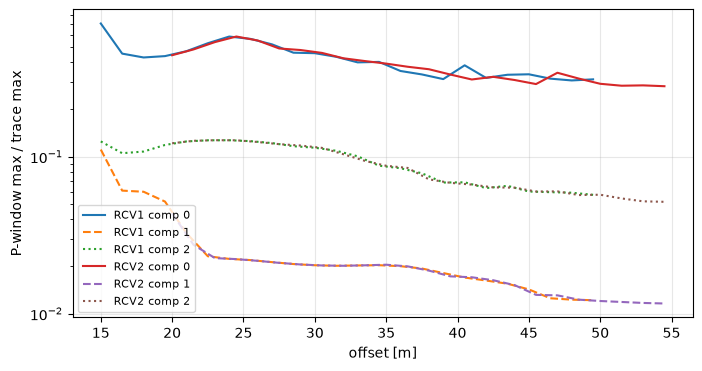

In [6]:
ratios = np.zeros(r.data.shape[:3])
for s in range(r.data.shape[0]):
    for rc in range(r.data.shape[1]):
        for c in range(3):
            e = r.eikonal[s, rc, min(c, 1)]
            m = (r.t > e - 1e-3) & (r.t < e + 1.5e-3)
            ratios[s, rc, c] = np.abs(r.data[s, rc, c][m]).max() / np.abs(r.data[s, rc, c]).max()
fig, ax = plt.subplots(figsize=(8, 4))
for rc in same_wall:
    for c, ls in zip(range(3), ['-', '--', ':']):
        ax.semilogy(r.offset[:, rc], ratios[:, rc, c], ls, label=f'{r.rcv_names[rc]} comp {c}')
ax.set_xlabel('offset [m]'); ax.set_ylabel('P-window max / trace max'); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.show()